# Exercise 3 - Edge Detection and Region Segmentation (BSDS)

This notebook implements Exercise 3 from Project1.pdf (assignment page 3; metric definitions on pages 5–6). It evaluates all six images and every human annotation. The required methods are Sobel, Prewitt, Laplacian, LoG, Otsu, adaptive thresholding, and K-means. Metrics use the definitions and edge-matching settings specified in the PDF.

This notebook follows the assignment from top to bottom:

1. Load images and display all human boundary and region annotations.
2. Detect edges with Sobel, Prewitt, Laplacian, and LoG zero crossings; compare sigma, kernel size, and threshold.
3. Segment regions with Otsu, adaptive thresholding, and K-means; compare relevant parameters.
4. Evaluate edge maps with ODS/AP and segmentations with Segmentation Covering/PRI using every human annotation.
5. Visualize three images and discuss successful and difficult cases.

By default, evaluation uses every available image/annotation pair. The notebook displays all six images for visual review. Set `IMAGE_IDS` below to restrict evaluation explicitly.

In [1]:
from pathlib import Path
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 100
N_IMAGES = None              # None loads the full set for dataset-level evaluation
IMAGE_IDS = None             # Example: ["01", "02", "03"]
TOL_FRAC = 0.0075            # 0.75% of the image diagonal
THRESHOLDS = np.linspace(0.01, 0.99, 99)


## 0.1 Load images and annotations

In [2]:
# Find the project root from the current notebook directory or its parents.
cwd = Path.cwd()
PROJECT_ROOT = next((p for p in (cwd, *cwd.parents)
    if (p / "3 Edge Detection and Region Segmentation" / "Input" / "Images").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot find the Exercise 3 Images folder from the current directory.")

IMAGE_DIR = PROJECT_ROOT / "3 Edge Detection and Region Segmentation" / "Input" / "Images"
GT_DIR = PROJECT_ROOT / "3 Edge Detection and Region Segmentation" / "Input" / "GroundTruth"
OUTPUT_DIR = PROJECT_ROOT / "3 Edge Detection and Region Segmentation" / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

image_files = {p.stem: p for p in IMAGE_DIR.glob("*.jpg")}
gt_files = {p.stem.removesuffix("GT"): p for p in GT_DIR.glob("*GT.npz")}
available_ids = sorted(set(image_files) & set(gt_files))
if not available_ids:
    raise FileNotFoundError(
        f"No matching image/annotation pairs found. Images: {IMAGE_DIR}; annotations: {GT_DIR}")

selected_ids = ([i for i in IMAGE_IDS if i in available_ids] if IMAGE_IDS
                else available_ids if N_IMAGES is None else available_ids[:N_IMAGES])
missing_ids = sorted(set(IMAGE_IDS or []) - set(available_ids))
if missing_ids:
    raise FileNotFoundError(f"Requested image IDs have no matching image and GT: {missing_ids}")
if not selected_ids:
    raise ValueError("No images selected. Check IMAGE_IDS and N_IMAGES.")

DATA = {}
for image_id in selected_ids:
    bgr = cv2.imread(str(image_files[image_id]), cv2.IMREAD_COLOR)
    if bgr is None:
        raise ValueError(f"Could not read image: {image_files[image_id]}")
    with np.load(gt_files[image_id]) as archive:
        if "boundaries" not in archive or "segmentations" not in archive:
            raise KeyError(f"{gt_files[image_id].name} must contain boundaries and segmentations")
        boundaries = archive["boundaries"]
        segmentations = archive["segmentations"]

    # The supplied dataset has two image orientations; transpose only when that
    # exactly matches the annotation shape.
    expected_shape = boundaries.shape[1:]
    if bgr.shape[:2] != expected_shape:
        if bgr.transpose(1, 0, 2).shape[:2] == expected_shape:
            bgr = bgr.transpose(1, 0, 2)
        else:
            raise ValueError(
                f"Shape mismatch for {image_id}: image {bgr.shape[:2]}, annotation {expected_shape}")
    if segmentations.shape[1:] != expected_shape:
        raise ValueError(f"Boundary/segmentation shape mismatch in {gt_files[image_id].name}")

    DATA[image_id] = {
        "rgb": cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB),
        "gray": cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY).astype(np.float32) / 255.0,
        "bnd": boundaries.astype(bool),
        "seg": segmentations.astype(np.int32),
    }
    print(f"{image_id}: image={bgr.shape[1]}x{bgr.shape[0]}, "
          f"boundary annotations={len(boundaries)}, "
          f"segmentation annotations={len(segmentations)}")

print(f"Loaded {len(DATA)} image(s) and all corresponding human annotations.")
print(f"Output folder: {OUTPUT_DIR}")


01: image=321x481, boundary annotations=5, segmentation annotations=5
02: image=321x481, boundary annotations=6, segmentation annotations=6
03: image=481x321, boundary annotations=5, segmentation annotations=5
04: image=481x321, boundary annotations=6, segmentation annotations=6
05: image=481x321, boundary annotations=5, segmentation annotations=5
06: image=321x481, boundary annotations=5, segmentation annotations=5
Loaded 6 image(s) and all corresponding human annotations.
Output folder: c:\Users\ADMIN\OneDrive\Desktop\Image Processing 1st Project- Ehsan Shafiei\3 Edge Detection and Region Segmentation\outputs


### Human annotations

Each column after the input shows one annotator in both rows: boundary map above, segmentation map below. The first column shows the input and average boundary agreement. Region colors are for display only.


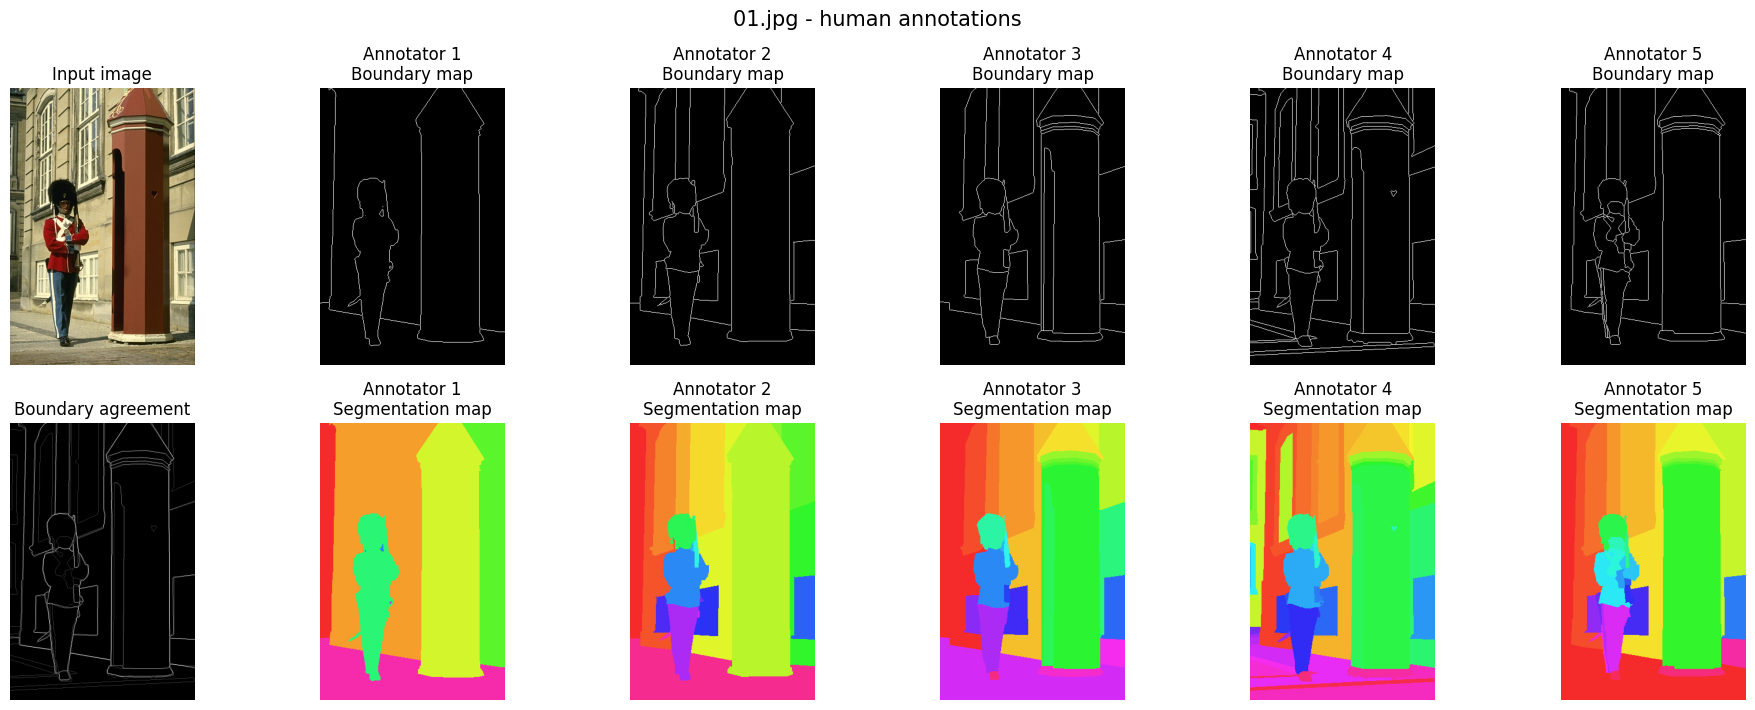

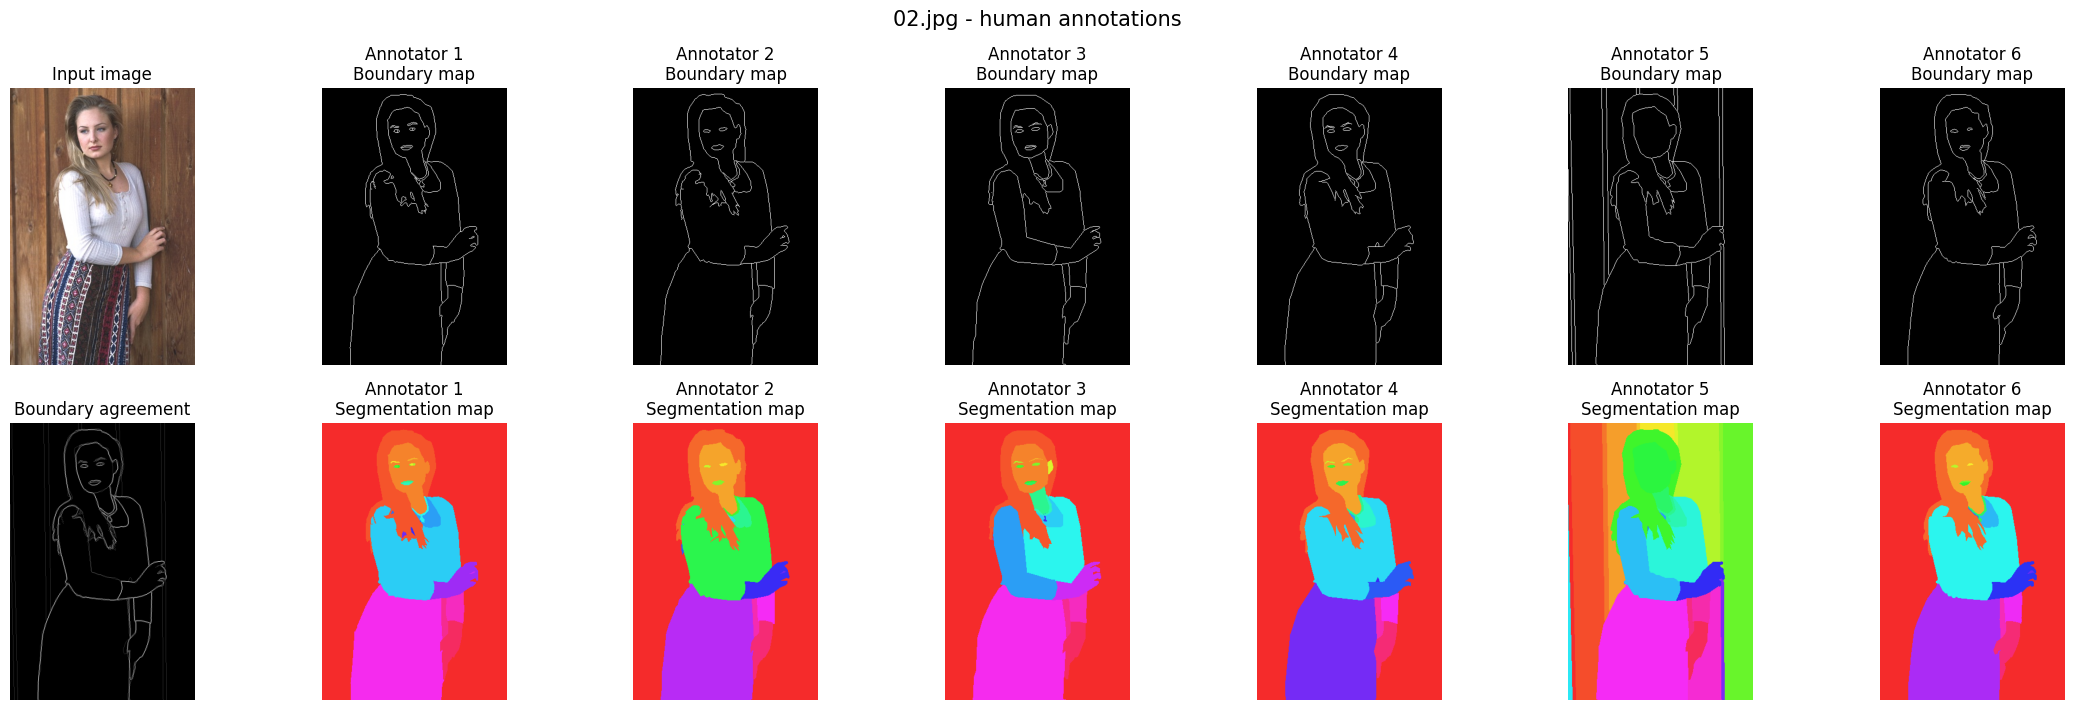

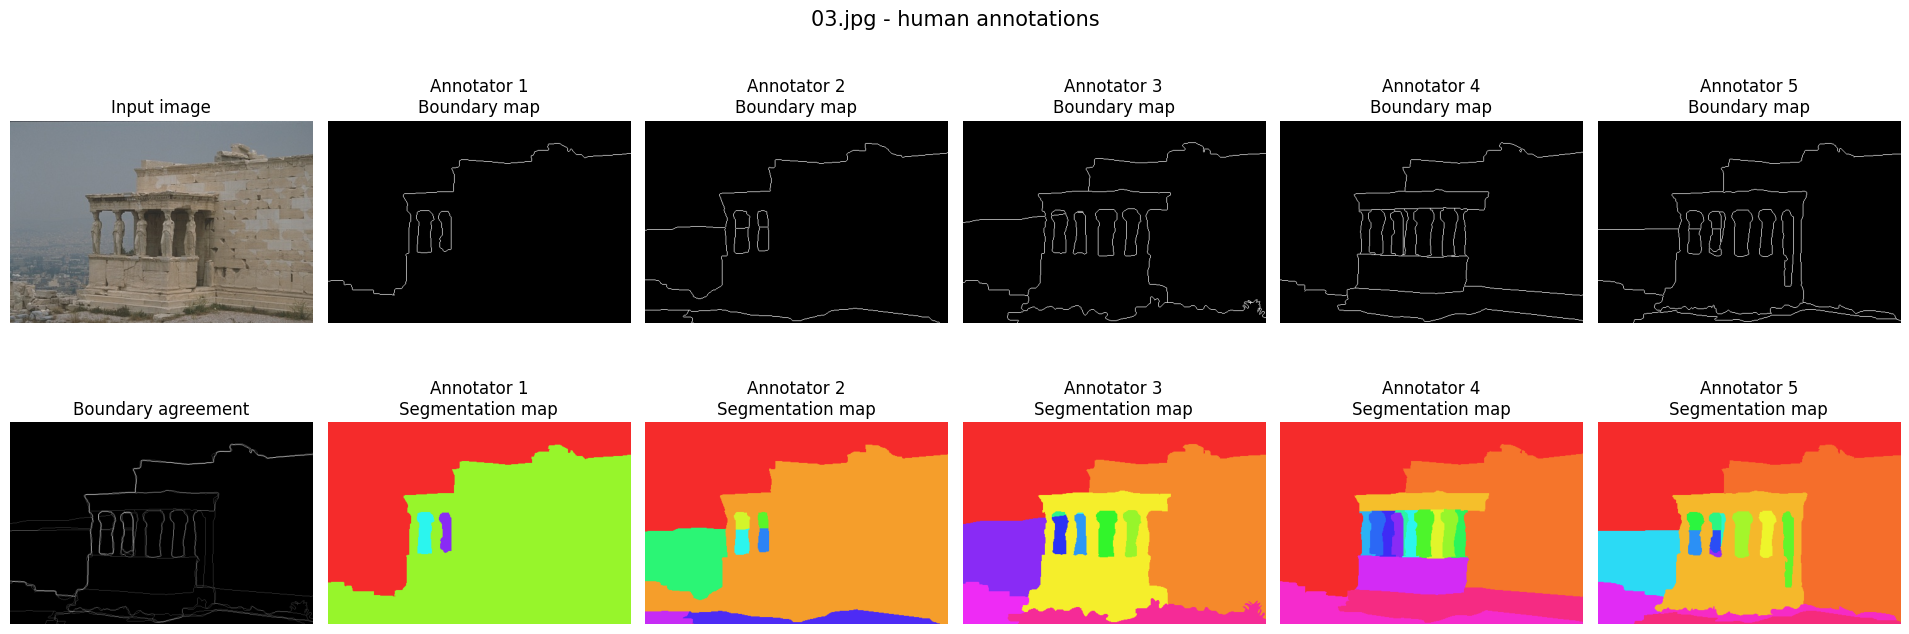

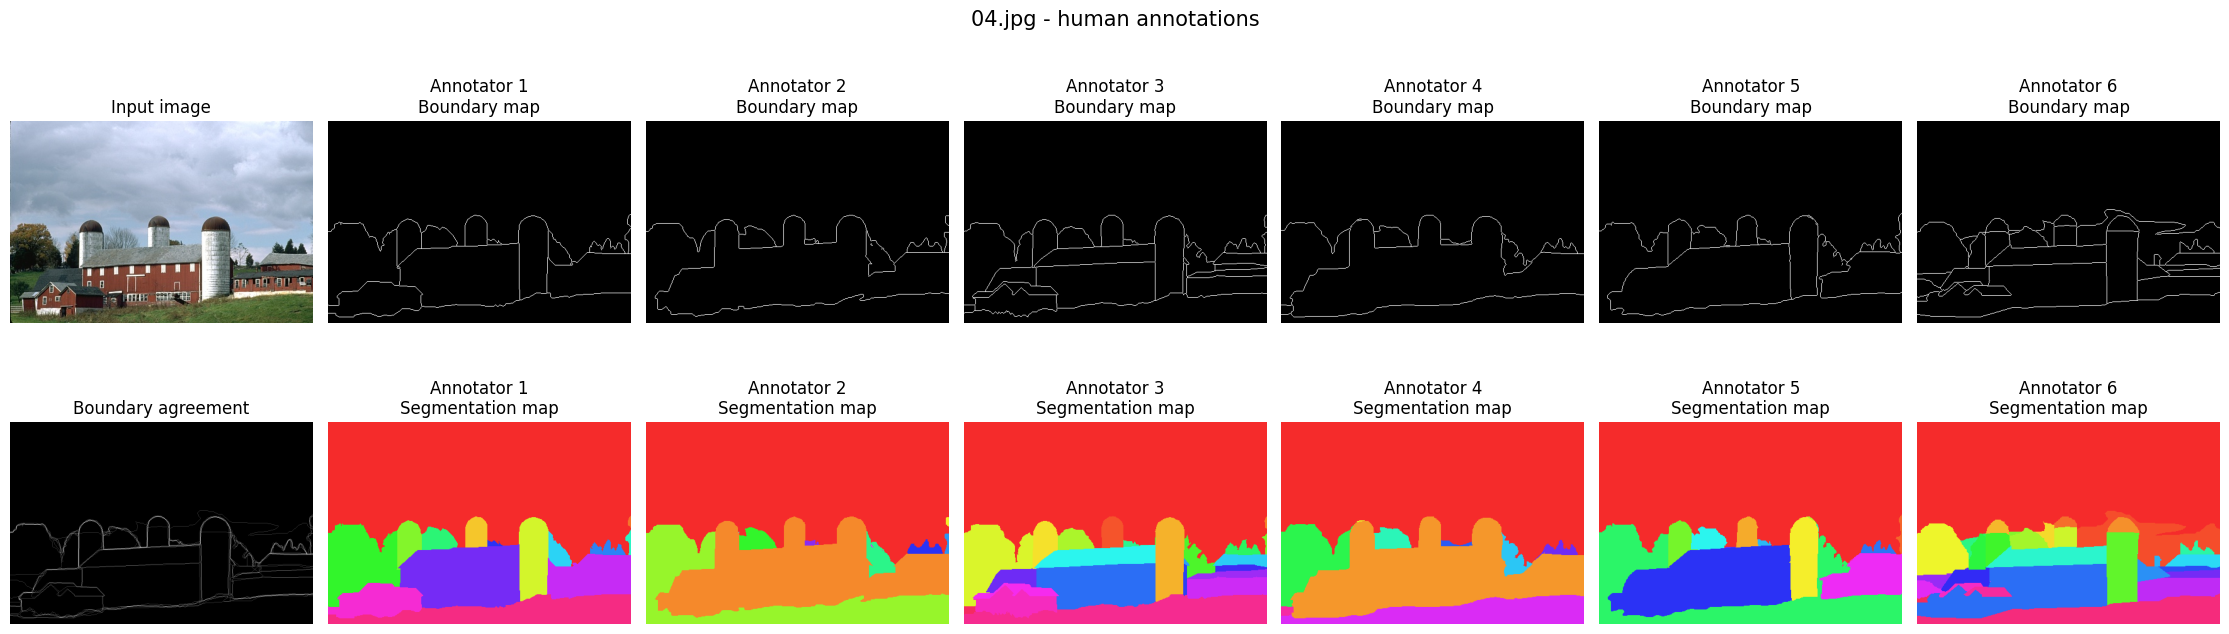

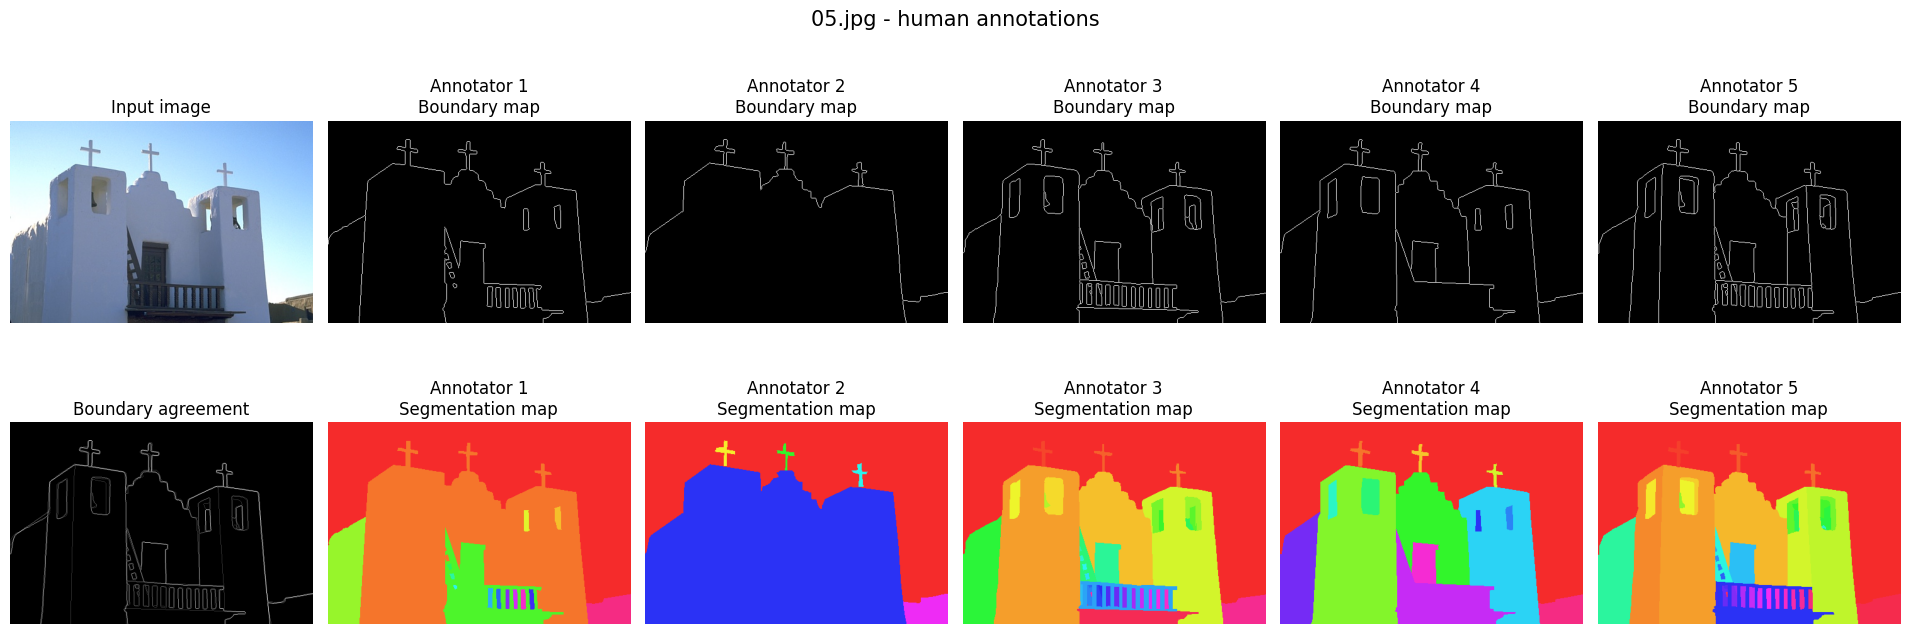

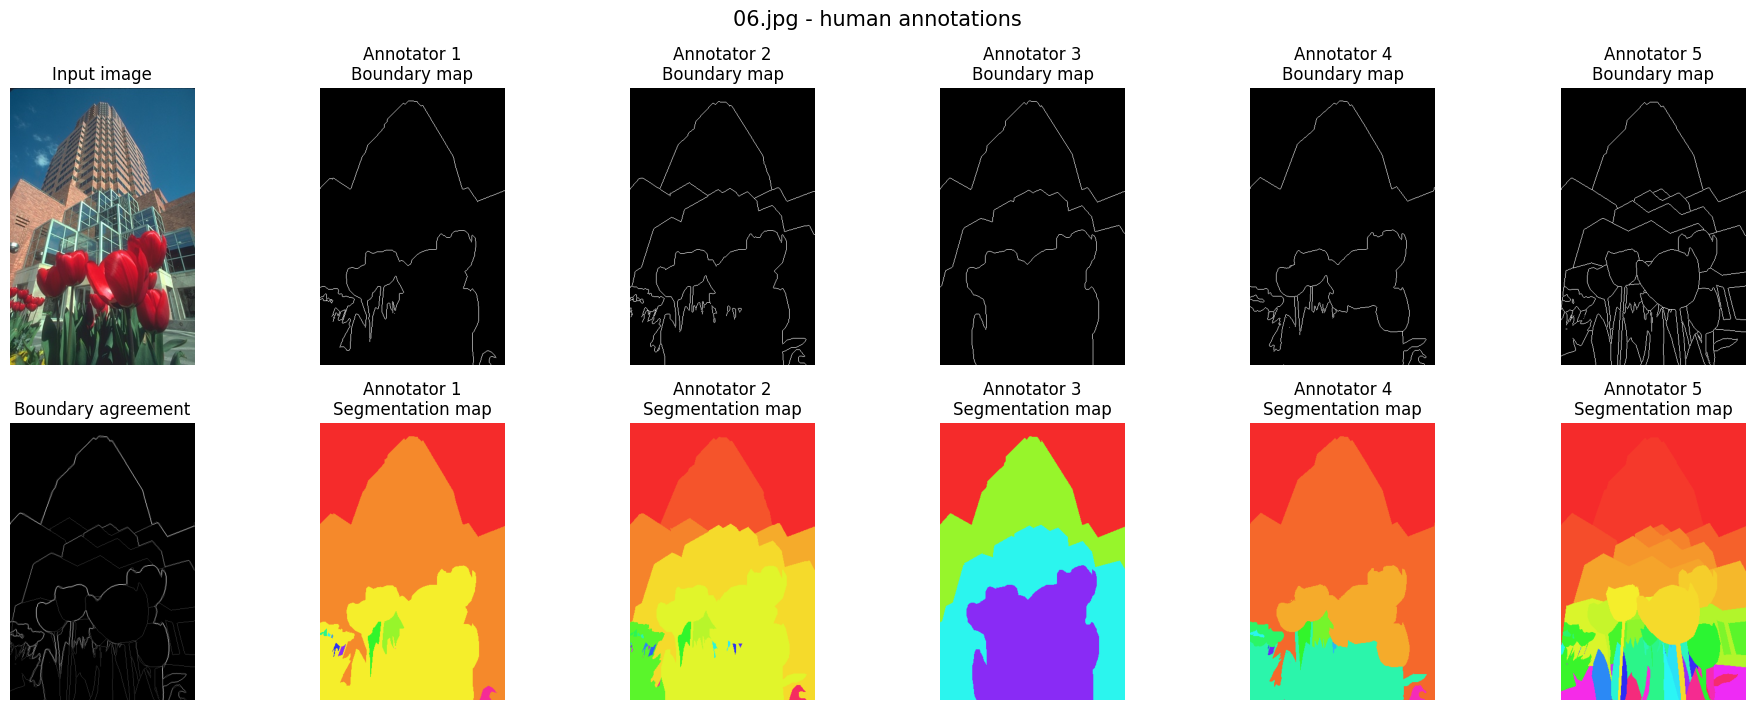

In [3]:
def colorize_labels(labels):
    """Give each distinct region its own stable, high-contrast display color."""
    labels = np.asarray(labels)
    _, inverse = np.unique(labels, return_inverse=True)
    region_count = int(inverse.max()) + 1
    # Spread colors across the hue wheel so small label IDs do not all look red.
    hsv = np.zeros((region_count, 1, 3), dtype=np.uint8)
    hsv[:, 0, 0] = np.linspace(0, 179, region_count, endpoint=False).astype(np.uint8)
    hsv[:, 0, 1] = 210
    hsv[:, 0, 2] = 245
    palette = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)[:, 0]
    return palette[inverse].reshape(*labels.shape, 3)


def show_annotations(image_id):
    data = DATA[image_id]
    count = data["bnd"].shape[0]
    fig, axes = plt.subplots(2, count + 1, figsize=(3.2 * (count + 1), 7.2))
    fig.suptitle(f"{image_id}.jpg - human annotations", fontsize=15)
    axes[0, 0].imshow(data["rgb"])
    axes[0, 0].set_title("Input image")
    axes[1, 0].imshow(data["bnd"].mean(axis=0), cmap="gray", vmin=0, vmax=1)
    axes[1, 0].set_title("Boundary agreement")
    for annotator in range(count):
        axes[0, annotator + 1].imshow(data["bnd"][annotator], cmap="gray")
        axes[0, annotator + 1].set_title(f"Annotator {annotator + 1}\nBoundary map")
        axes[1, annotator + 1].imshow(colorize_labels(data["seg"][annotator]))
        axes[1, annotator + 1].set_title(f"Annotator {annotator + 1}\nSegmentation map")
    for ax in axes.ravel():
        ax.axis("off")
    plt.tight_layout()
    plt.show()

for image_id in list(DATA):
    show_annotations(image_id)


## 1. Edge detection

- **Sobel / Prewitt:** gradient magnitude, thresholded and thinned to obtain boundary pixels.
- **Laplacian:** optional Gaussian smoothing followed by Laplacian zero-crossing detection.
- **LoG:** Laplacian-of-Gaussian response at a selected sigma, followed by zero-crossing detection.
- At a zero crossing, edge strength is measured from the response change so the threshold can suppress weak crossings.
- Responses are normalized to [0, 1] using the 99.9th percentile, making thresholds comparable.

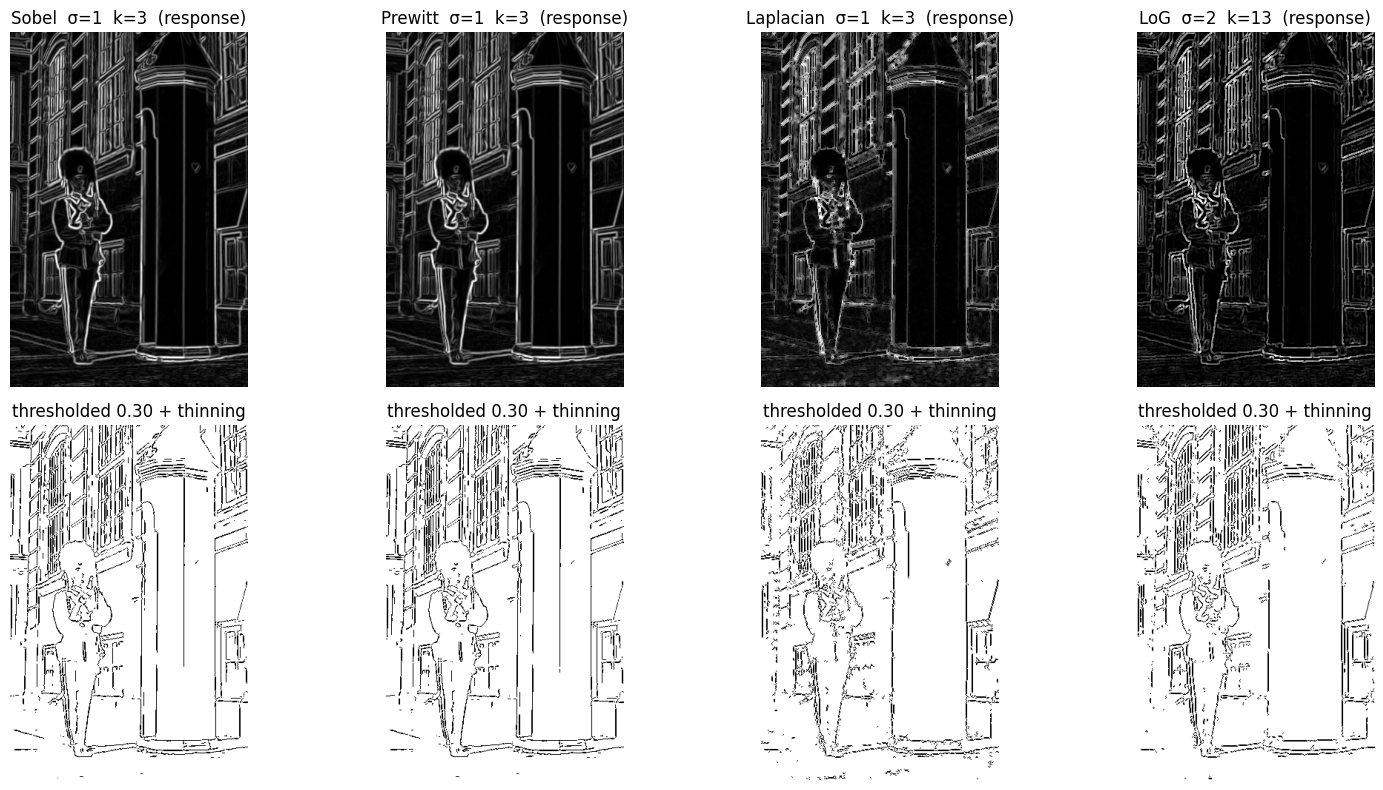

In [4]:
def norm(r, q=99.9):
    p = np.percentile(r, q)
    return np.clip(r / p, 0, 1).astype(np.float32) if p > 0 else np.zeros_like(r, np.float32)

def gauss(g, sigma, ksize=None):
    if sigma <= 0: return g
    k = ksize or 2*int(np.ceil(3*sigma))+1
    return cv2.GaussianBlur(g, (k, k), sigmaX=sigma, sigmaY=sigma)

def zero_crossing_strength(L):
    """Edge strength at sign changes of L (4 neighbour directions), = max |L| jump across the crossing."""
    out = np.zeros_like(L)
    h, w = L.shape
    for dy, dx in ((0,1),(1,0),(1,1),(1,-1)):
        ys, ye = max(0,-dy), min(h,h-dy); xs, xe = max(0,-dx), min(w,w-dx)
        a = L[ys:ye, xs:xe]; b = L[ys+dy:ye+dy, xs+dx:xe+dx]
        cross = (a*b) < 0
        v = np.where(cross, np.abs(a-b), 0)
        out[ys:ye, xs:xe] = np.maximum(out[ys:ye, xs:xe], v)
        out[ys+dy:ye+dy, xs+dx:xe+dx] = np.maximum(out[ys+dy:ye+dy, xs+dx:xe+dx], v)
    return out

def prewitt_kernel(k):
    h = k//2
    d = np.r_[-np.ones(h), 0, np.ones(h)].astype(np.float32)
    return np.tile(d, (k,1)) / (k*h*2)

def log_kernel(sigma, ksize=None):
    k = ksize or (2*int(np.ceil(3*sigma))+1)
    r = np.arange(k) - k//2
    x, y = np.meshgrid(r, r)
    s2 = sigma**2
    K = ((x**2 + y**2 - 2*s2) / s2**2) * np.exp(-(x**2 + y**2)/(2*s2))
    return (K - K.mean()).astype(np.float32)      # zero-sum kernel

def edge_response(gray, method, sigma=0.0, ksize=3):
    g = gauss(gray, sigma)
    if method == "Sobel":
        gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=ksize); gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=ksize)
        return norm(np.hypot(gx, gy))
    if method == "Prewitt":
        kx = prewitt_kernel(ksize)
        gx = cv2.filter2D(g, cv2.CV_32F, kx); gy = cv2.filter2D(g, cv2.CV_32F, kx.T)
        return norm(np.hypot(gx, gy))
    if method == "Laplacian":
        return norm(zero_crossing_strength(cv2.Laplacian(g, cv2.CV_32F, ksize=ksize)))
    if method == "LoG":
        return norm(zero_crossing_strength(cv2.filter2D(gray, cv2.CV_32F, log_kernel(sigma, ksize))))
    raise ValueError(method)

def thin_edges(binary_map):
    """Morphological skeleton: iteratively erode and collect boundary residue."""
    current = binary_map.astype(np.uint8)
    skeleton = np.zeros_like(current)
    element = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
    while cv2.countNonZero(current):
        eroded = cv2.erode(current, element)
        opened = cv2.dilate(eroded, element)
        residue = cv2.subtract(current, opened)
        skeleton = cv2.bitwise_or(skeleton, residue)
        current = eroded
    return skeleton.astype(bool)


def binarize_edges(resp, threshold, do_thin=True):
    binary = resp >= threshold
    return thin_edges(binary) if do_thin else binary

# quick look at all four operators on the first image
i0 = next(iter(DATA)); g0 = DATA[i0]["gray"]
fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for c, (m, s, k) in enumerate([("Sobel",1,3),("Prewitt",1,3),("Laplacian",1,3),("LoG",2,13)]):
    r = edge_response(g0, m, s, k)
    ax[0,c].imshow(r, cmap="gray");  ax[0,c].set_title(f"{m}  σ={s}  k={k}  (response)")
    ax[1,c].imshow(~binarize_edges(r, 0.3), cmap="gray"); ax[1,c].set_title("thresholded 0.30 + thinning")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

### Edge metrics: ODS and AP

At each threshold, detected boundaries are compared with all human annotations using a tolerance of 0.75% of the image diagonal.

- **Precision:** fraction of predicted edge pixels near a human boundary.
- **Recall:** fraction of human boundary pixels near a predicted edge, averaged over annotators.
- **ODS:** best dataset-level F-measure using one shared threshold.
- **AP:** area under the interpolated precision-recall curve.

This notebook uses distance-transform matching as a practical approximation to exact BSDS bipartite matching.

In [5]:
def prep_gt(d):
    tol = TOL_FRAC * np.hypot(*d["gray"].shape)
    d["tol"] = tol
    d["dt_gt"] = [cv2.distanceTransform((~b).astype(np.uint8), cv2.DIST_L2, 3) for b in d["bnd"]]    # distance to each annotator's boundary
    d["dt_gt_min"] = np.minimum.reduce(d["dt_gt"])
for d in DATA.values(): prep_gt(d)

def boundary_counts(pred, d):
    dt_pred = cv2.distanceTransform((~pred).astype(np.uint8), cv2.DIST_L2, 3)
    tp_p = (pred & (d["dt_gt_min"] <= d["tol"])).sum(); n_p = pred.sum()
    tp_r = sum((b & (dt_pred <= d["tol"])).sum() for b in d["bnd"]); n_r = sum(b.sum() for b in d["bnd"])
    return tp_p, n_p, tp_r, n_r

def pr_curve(resp_by_img, thresholds=THRESHOLDS):
    rows = []
    for t in thresholds:
        S = np.zeros(4)
        for i, resp in resp_by_img.items():
            S += boundary_counts(binarize_edges(resp, t), DATA[i])
        P = S[0]/max(S[1],1); R = S[2]/max(S[3],1)
        rows.append((t, P, R, 2*P*R/(P+R) if P+R > 0 else 0))
    return pd.DataFrame(rows, columns=["thr","P","R","F"])

def ods_ap(pr):
    ods = pr.F.max()
    R = np.r_[0, pr.R.values, 1][np.argsort(np.r_[0, pr.R.values, 1])]
    P = np.r_[1, pr.P.values, 0][np.argsort(np.r_[0, pr.R.values, 1])]
    P = np.maximum.accumulate(P[::-1])[::-1]          # precision envelope
    return ods, (np.trapezoid if hasattr(np,"trapezoid") else np.trapz)(P, R), pr.thr[pr.F.idxmax()]

### Parameter study: sigma, kernel size, and threshold

In [6]:
EDGE_CONFIGS = []
for method in ("Sobel", "Prewitt", "Laplacian"):
    EDGE_CONFIGS.extend([
        (method, 0, 3),  # no smoothing, 3x3 kernel
        (method, 1, 3),  # sigma=1, 3x3 kernel
        (method, 0, 5),  # no smoothing, 5x5 kernel
    ])
for sigma in (1, 2):
    EDGE_CONFIGS.append(("LoG", sigma, 2 * int(np.ceil(3 * sigma)) + 1))

edge_rows, edge_pr = [], {}
for method, sigma, kernel_size in EDGE_CONFIGS:
    response = {image_id: edge_response(data["gray"], method, sigma, kernel_size)
                for image_id, data in DATA.items()}
    curve = pr_curve(response)
    ods, ap, best_threshold = ods_ap(curve)
    edge_pr[(method, sigma, kernel_size)] = curve
    edge_rows.append({"method":method, "sigma":sigma, "ksize":kernel_size,
                      "ODS":round(ods, 3), "AP":round(ap, 3),
                      "best_threshold":round(best_threshold, 2)})
edge_df = pd.DataFrame(edge_rows)
display(edge_df.sort_values("ODS", ascending=False).reset_index(drop=True))


,method,sigma,ksize,ODS,AP,best_threshold
0,Prewitt,1,3,0.691,0.615,0.22
1,Prewitt,0,5,0.690,0.608,0.23
2,Sobel,1,3,0.690,0.614,0.22
3,Sobel,0,5,0.688,0.599,0.22
4,Prewitt,0,3,0.682,0.577,0.20
5,Sobel,0,3,0.681,0.576,0.19
6,LoG,2,13,0.676,0.568,0.15
7,Laplacian,1,3,0.674,0.566,0.15
8,LoG,1,7,0.668,0.560,0.14
9,Laplacian,0,5,0.665,0.556,0.15


Best configuration per method:


,method,sigma,ksize,ODS,AP,best_threshold
0,Laplacian,1,3,0.674,0.566,0.15
1,LoG,2,13,0.676,0.568,0.15
2,Prewitt,1,3,0.691,0.615,0.22
3,Sobel,1,3,0.690,0.614,0.22


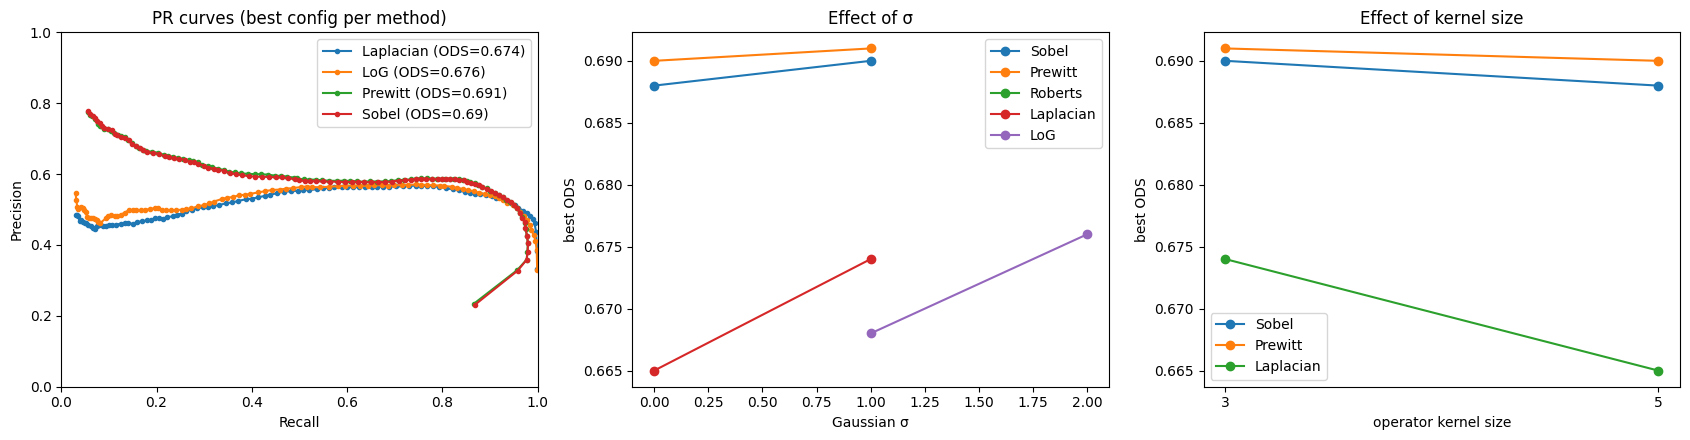

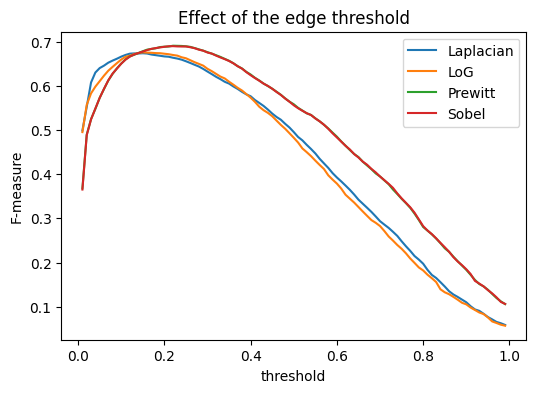

In [7]:
best_edge = edge_df.loc[edge_df.groupby("method").ODS.idxmax()].reset_index(drop=True)
print("Best configuration per method:"); display(best_edge)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for _, r in best_edge.iterrows():
    pr = edge_pr[(r.method, r.sigma, r.ksize)]
    ax[0].plot(pr.R, pr.P, marker=".", label=f"{r.method} (ODS={r.ODS})")
ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision"); ax[0].set_title("PR curves (best config per method)")
ax[0].set_xlim(0,1); ax[0].set_ylim(0,1); ax[0].legend()
for m in ("Sobel","Prewitt","Roberts","Laplacian","LoG"):
    sub = edge_df[edge_df.method==m].groupby("sigma").ODS.max(); ax[1].plot(sub.index, sub.values, marker="o", label=m)
ax[1].set_xlabel("Gaussian σ"); ax[1].set_ylabel("best ODS"); ax[1].set_title("Effect of σ"); ax[1].legend()
for m in ("Sobel","Prewitt","Laplacian"):
    sub = edge_df[edge_df.method==m].groupby("ksize").ODS.max(); ax[2].plot(sub.index, sub.values, marker="o", label=m)
ax[2].set_xticks([3,5]); ax[2].set_xlabel("operator kernel size"); ax[2].set_ylabel("best ODS"); ax[2].set_title("Effect of kernel size"); ax[2].legend()
plt.tight_layout(); plt.show()

# effect of threshold: F-measure vs threshold for the best config of every method
plt.figure(figsize=(6,4))
for _, r in best_edge.iterrows():
    pr = edge_pr[(r.method, r.sigma, r.ksize)]; plt.plot(pr.thr, pr.F, label=r.method)
plt.xlabel("threshold"); plt.ylabel("F-measure"); plt.title("Effect of the edge threshold"); plt.legend(); plt.show()

### Visual edge comparison on the images (best configuration per method at its ODS threshold)

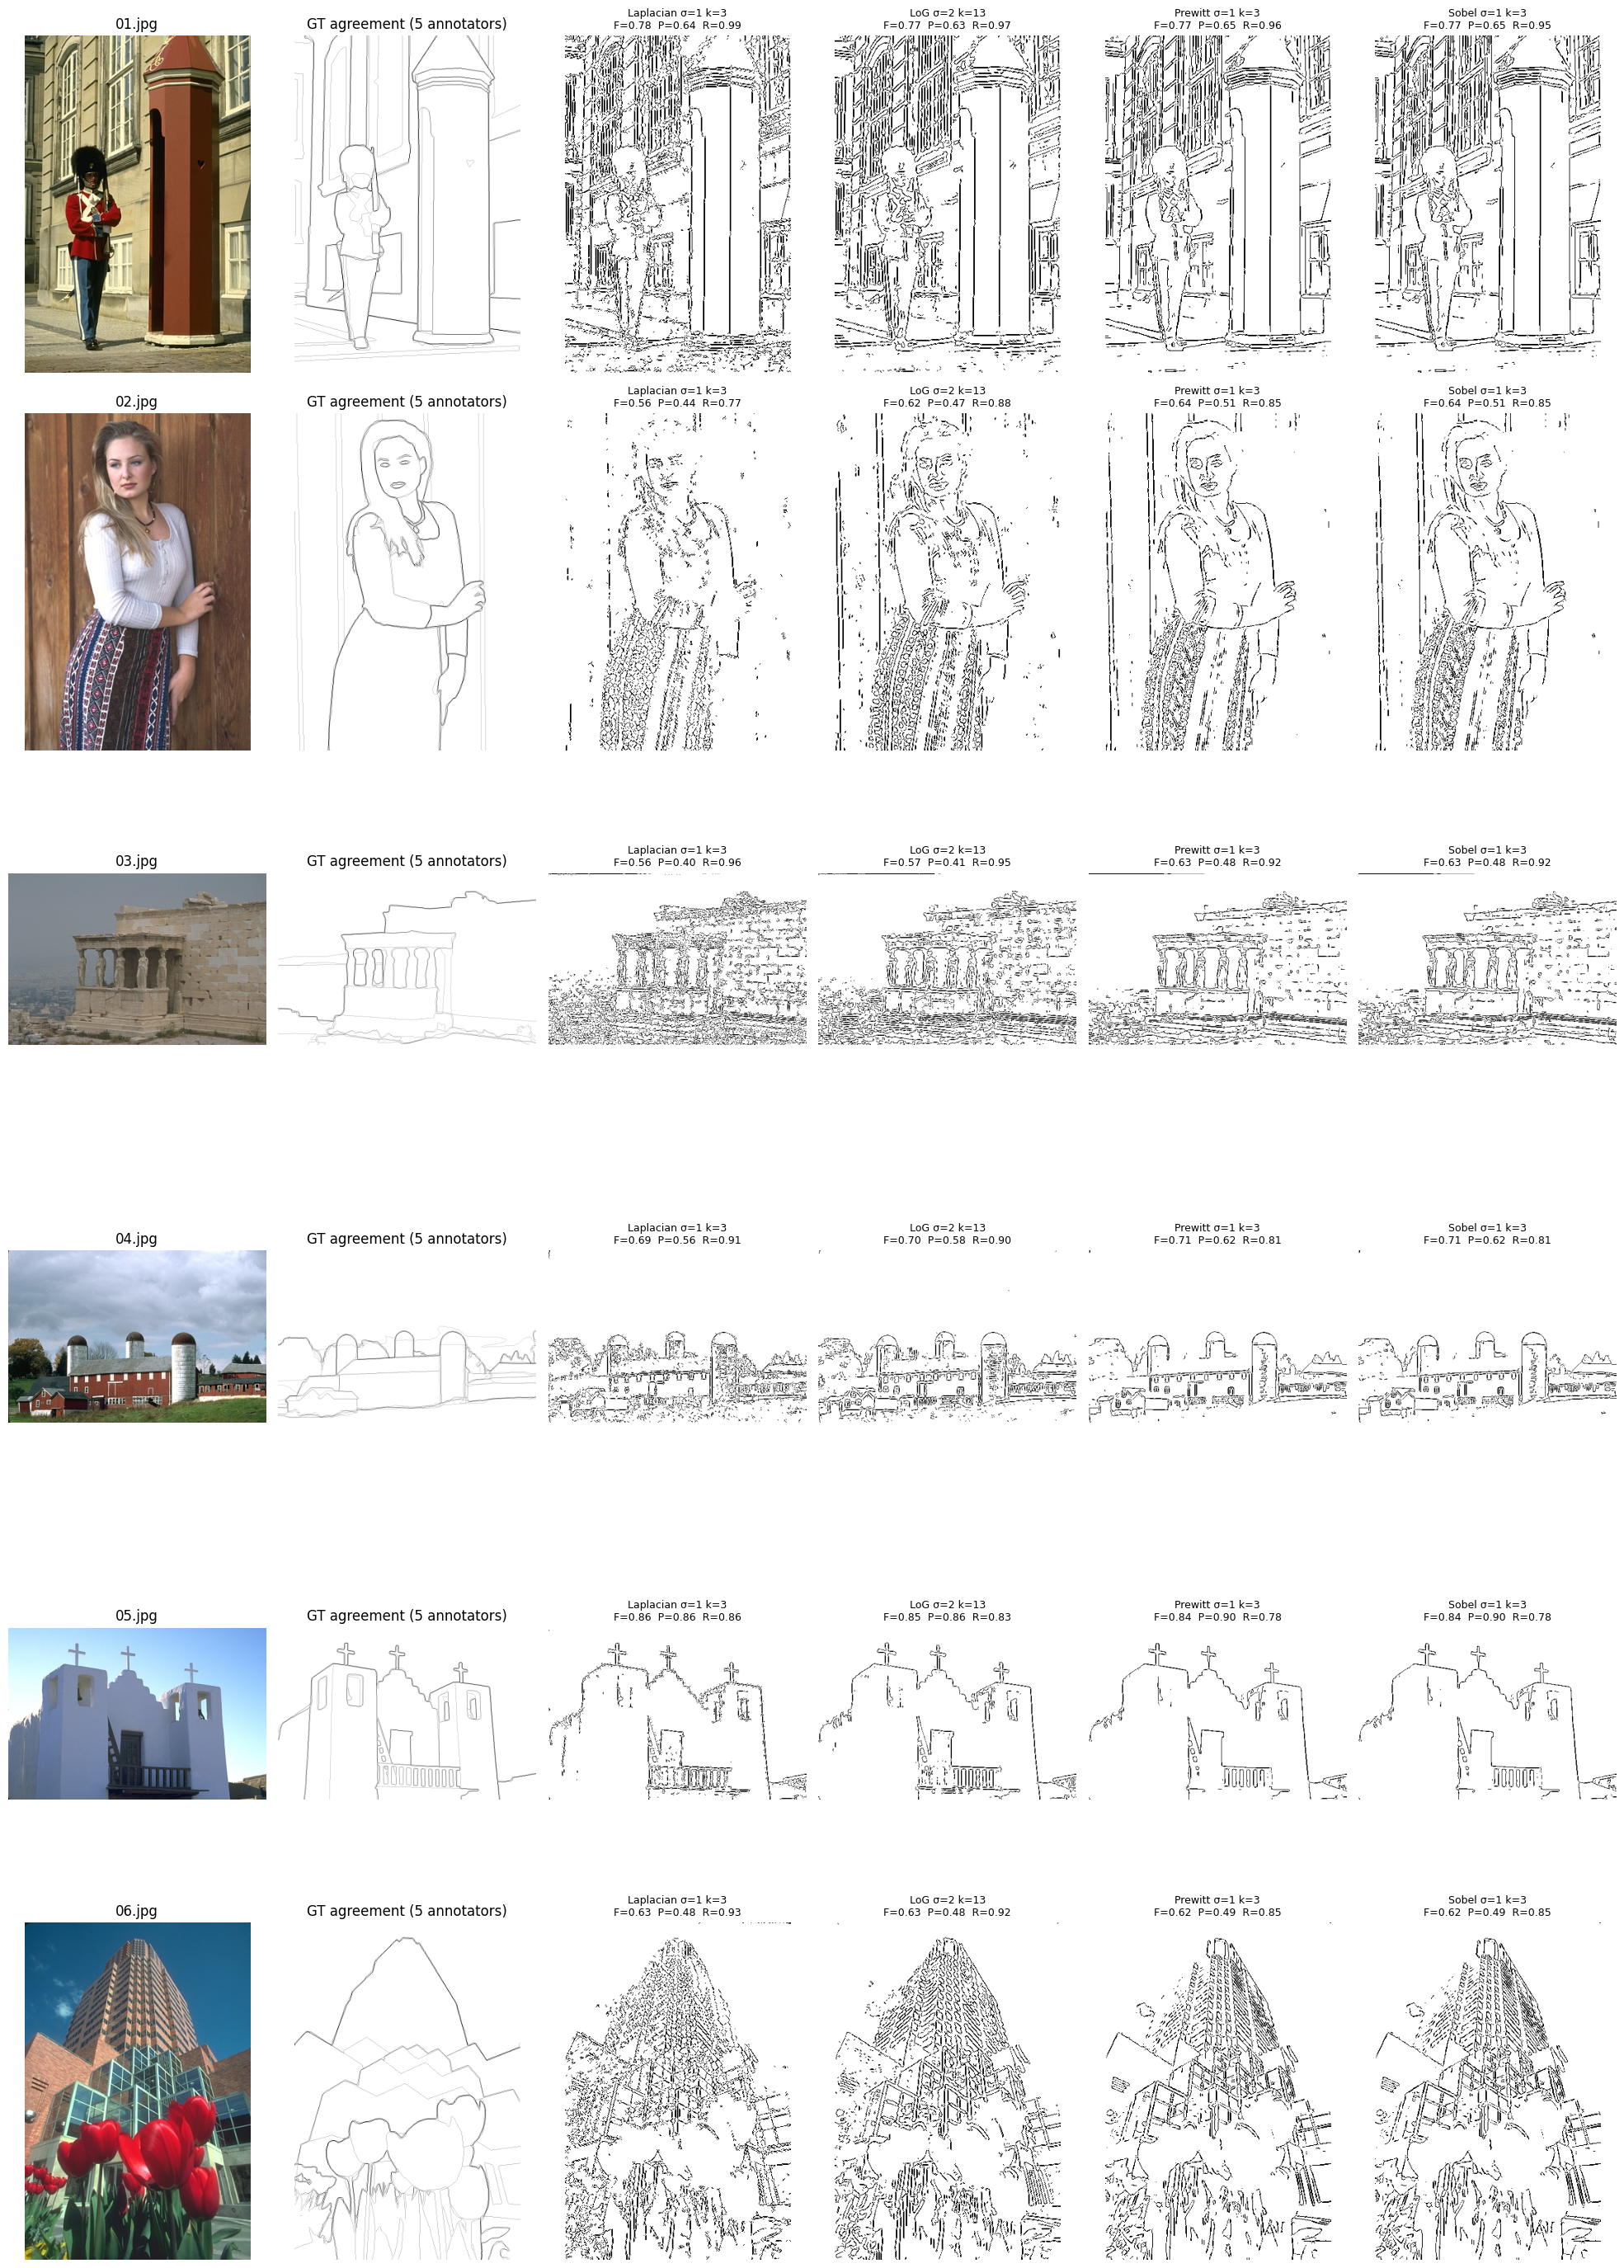

In [8]:
meths = list(best_edge.method)
DISPLAY_IDS = list(DATA)
fig, ax = plt.subplots(len(DISPLAY_IDS), 2+len(meths), figsize=(3.3*(2+len(meths)), 4.6*len(DISPLAY_IDS)), squeeze=False)
edge_img_scores = {}
for r_i, i in enumerate(DISPLAY_IDS):
    d = DATA[i]
    ax[r_i,0].imshow(d["rgb"]); ax[r_i,0].set_title(f"{i}.jpg")
    ax[r_i,1].imshow(d["bnd"].mean(0), cmap="gray_r"); ax[r_i,1].set_title("GT agreement (5 annotators)")
    for c, (_, r) in enumerate(best_edge.iterrows()):
        e = binarize_edges(edge_response(d["gray"], r.method, r.sigma, r.ksize), r.best_threshold)
        tp_p, n_p, tp_r, n_r = boundary_counts(e, d)
        P, R = tp_p/max(n_p,1), tp_r/max(n_r,1); F = 2*P*R/(P+R+1e-9)
        edge_img_scores[(i, r.method)] = F
        ax[r_i,c+2].imshow(~e, cmap="gray")
        ax[r_i,c+2].set_title(f"{r.method} σ={r.sigma} k={r.ksize}\nF={F:.2f}  P={P:.2f}  R={R:.2f}", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 2. Region segmentation

- **Otsu:** global two-class thresholding with OpenCV.
- **Adaptive thresholding:** local mean or Gaussian threshold; vary window size and offset `C`.
- **K-means:** OpenCV clustering of Lab color pixels; vary cluster count `K`.

These are the assignment’s classical methods. We do not add connected-component cleanup, pretrained models, or extra clustering features.

In [9]:
def segment_otsu(data, sigma=0):
    gray = gauss(data["gray"], sigma)
    gray8 = np.clip(gray * 255, 0, 255).astype(np.uint8)
    _, labels = cv2.threshold(gray8, 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return labels.astype(np.int32)


def segment_adaptive(data, block=31, C=5, method="gaussian"):
    gray8 = np.clip(data["gray"] * 255, 0, 255).astype(np.uint8)
    adaptive_method = (cv2.ADAPTIVE_THRESH_GAUSSIAN_C if method == "gaussian"
                       else cv2.ADAPTIVE_THRESH_MEAN_C)
    labels = cv2.adaptiveThreshold(gray8, 1, adaptive_method,
                                  cv2.THRESH_BINARY, block, C)
    return labels.astype(np.int32)


def segment_kmeans(data, k=4):
    lab = cv2.cvtColor(data["rgb"], cv2.COLOR_RGB2LAB).astype(np.float32)
    pixels = lab.reshape(-1, 3)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 1.0)
    cv2.setRNGSeed(0)
    _, labels, _ = cv2.kmeans(pixels, k, None, criteria, 1,
                               cv2.KMEANS_PP_CENTERS)
    return labels.reshape(lab.shape[:2]).astype(np.int32)


### Region metrics: Segmentation Covering and PRI

For each human segmentation, the notebook builds a contingency table between the machine segmentation `S` and the reference `G`.

- **Segmentation Covering:** area-weighted best intersection-over-union (IoU) for each reference region, averaged across annotators.
- **PRI:** pairwise Rand agreement between the prediction and each human annotation, averaged across annotators.

In [10]:
def contingency(a, b):
    a = np.unique(a.ravel(), return_inverse=True)[1]; b = np.unique(b.ravel(), return_inverse=True)[1]
    na, nb = a.max()+1, b.max()+1
    return np.bincount(a*nb+b, minlength=na*nb).reshape(na, nb).astype(np.float64)

def covering(gt, pred):
    M = contingency(gt, pred); sg, sp = M.sum(1, keepdims=True), M.sum(0, keepdims=True)
    iou = M / (sg + sp - M)
    return (sg.ravel() * iou.max(1)).sum() / M.sum()

def rand_index(gt, pred):
    M = contingency(gt, pred); N = M.sum()
    c2 = lambda x: (x*(x-1)/2).sum()
    tot = N*(N-1)/2; same_both = c2(M); same_g = c2(M.sum(1)); same_p = c2(M.sum(0))
    return (tot + 2*same_both - same_g - same_p) / tot

def seg_scores(pred, d):
    sc = [covering(g, pred) for g in d["seg"]]; ri = [rand_index(g, pred) for g in d["seg"]]
    return dict(SC=np.mean(sc), PRI=np.mean(ri), SC_each=sc, PRI_each=ri)

### Parameter study: threshold, local window size, and number of clusters

In [11]:
SEG_CONFIGS = [("Otsu", {"sigma": 0})]
for method in ("gaussian", "mean"):
    for block, c_value in ((15, 5), (31, 5), (51, 5), (31, 0), (31, 10)):
        SEG_CONFIGS.append(("Adaptive", {"block":block, "C":c_value, "method":method}))
for k in (2, 3, 4, 6):
    SEG_CONFIGS.append(("K-means", {"k":k}))

SEGMENTERS = {"Otsu":segment_otsu, "Adaptive":segment_adaptive,
              "K-means":segment_kmeans}
seg_rows = []
for method, params in SEG_CONFIGS:
    scores = [seg_scores(SEGMENTERS[method](data, **params), data)
              for data in DATA.values()]
    seg_rows.append({"method":method, "params":str(params),
                     "SC":round(float(np.mean([x["SC"] for x in scores])), 3),
                     "PRI":round(float(np.mean([x["PRI"] for x in scores])), 3),
                     "_params":params})
seg_df = pd.DataFrame(seg_rows)
display(seg_df.drop(columns="_params").sort_values("SC",ascending=False).reset_index(drop=True))


,method,params,SC,PRI
0,Otsu,{'sigma': 0},0.394,0.602
1,K-means,{'k': 2},0.394,0.607
2,K-means,{'k': 6},0.376,0.745
3,K-means,{'k': 3},0.372,0.660
4,K-means,{'k': 4},0.365,0.699
5,Adaptive,"{'block': 31, 'C': 10, 'method': 'mean'}",0.295,0.501
6,Adaptive,"{'block': 31, 'C': 10, 'method': 'gaussian'}",0.294,0.473
7,Adaptive,"{'block': 15, 'C': 5, 'method': 'gaussian'}",0.292,0.484
8,Adaptive,"{'block': 31, 'C': 5, 'method': 'gaussian'}",0.290,0.506
9,Adaptive,"{'block': 15, 'C': 5, 'method': 'mean'}",0.289,0.502


Best configuration per method (by Segmentation Covering):


,method,params,SC,PRI
0,Adaptive,"{'block': 31, 'C': 10, 'method': 'mean'}",0.295,0.501
1,K-means,{'k': 2},0.394,0.607
2,Otsu,{'sigma': 0},0.394,0.602


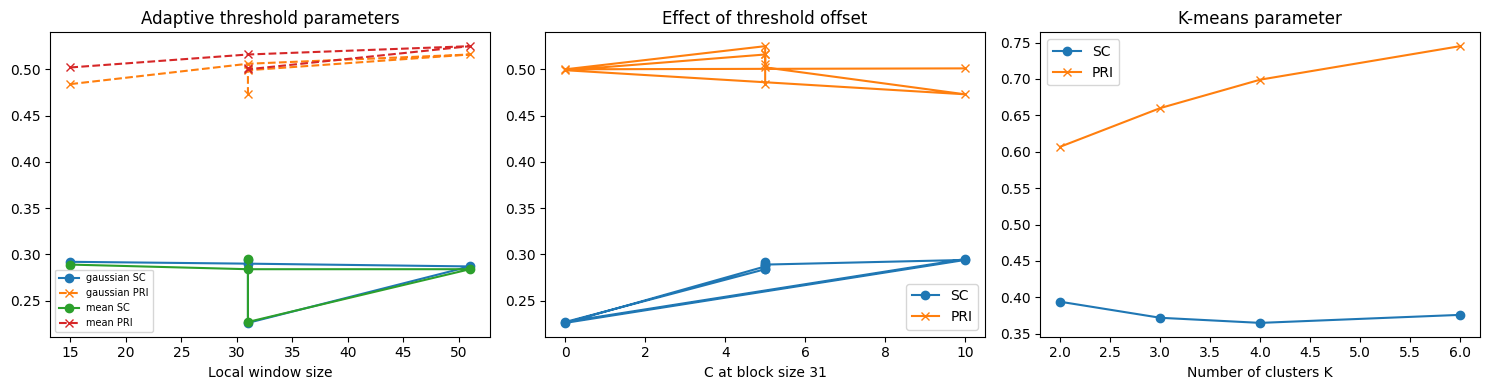

In [12]:
best_seg = seg_df.loc[seg_df.groupby("method").SC.idxmax()].reset_index(drop=True)
print("Best configuration per method (by Segmentation Covering):")
display(best_seg.drop(columns="_params"))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
adaptive = seg_df[seg_df.method == "Adaptive"].copy()
adaptive["block"] = adaptive._params.map(lambda p:p.get("block"))
adaptive["C"] = adaptive._params.map(lambda p:p.get("C"))
for method, group in adaptive.groupby(adaptive._params.map(lambda p:p["method"])):
    axes[0].plot(group.block, group.SC, marker="o", label=f"{method} SC")
    axes[0].plot(group.block, group.PRI, marker="x", linestyle="--", label=f"{method} PRI")
axes[0].set_xlabel("Local window size"); axes[0].set_title("Adaptive threshold parameters"); axes[0].legend(fontsize=7)
for metric, marker in (("SC","o"),("PRI","x")):
    axes[1].plot(adaptive.C, adaptive[metric], marker=marker, label=metric)
axes[1].set_xlabel("C at block size 31"); axes[1].set_title("Effect of threshold offset"); axes[1].legend()
km = seg_df[seg_df.method == "K-means"].copy(); km["K"] = km._params.map(lambda p:p["k"])
axes[2].plot(km.K, km.SC, marker="o", label="SC")
axes[2].plot(km.K, km.PRI, marker="x", label="PRI")
axes[2].set_xlabel("Number of clusters K"); axes[2].set_title("K-means parameter"); axes[2].legend()
plt.tight_layout(); plt.show()


### Visual segmentation results (best configuration per method) compared with human annotations

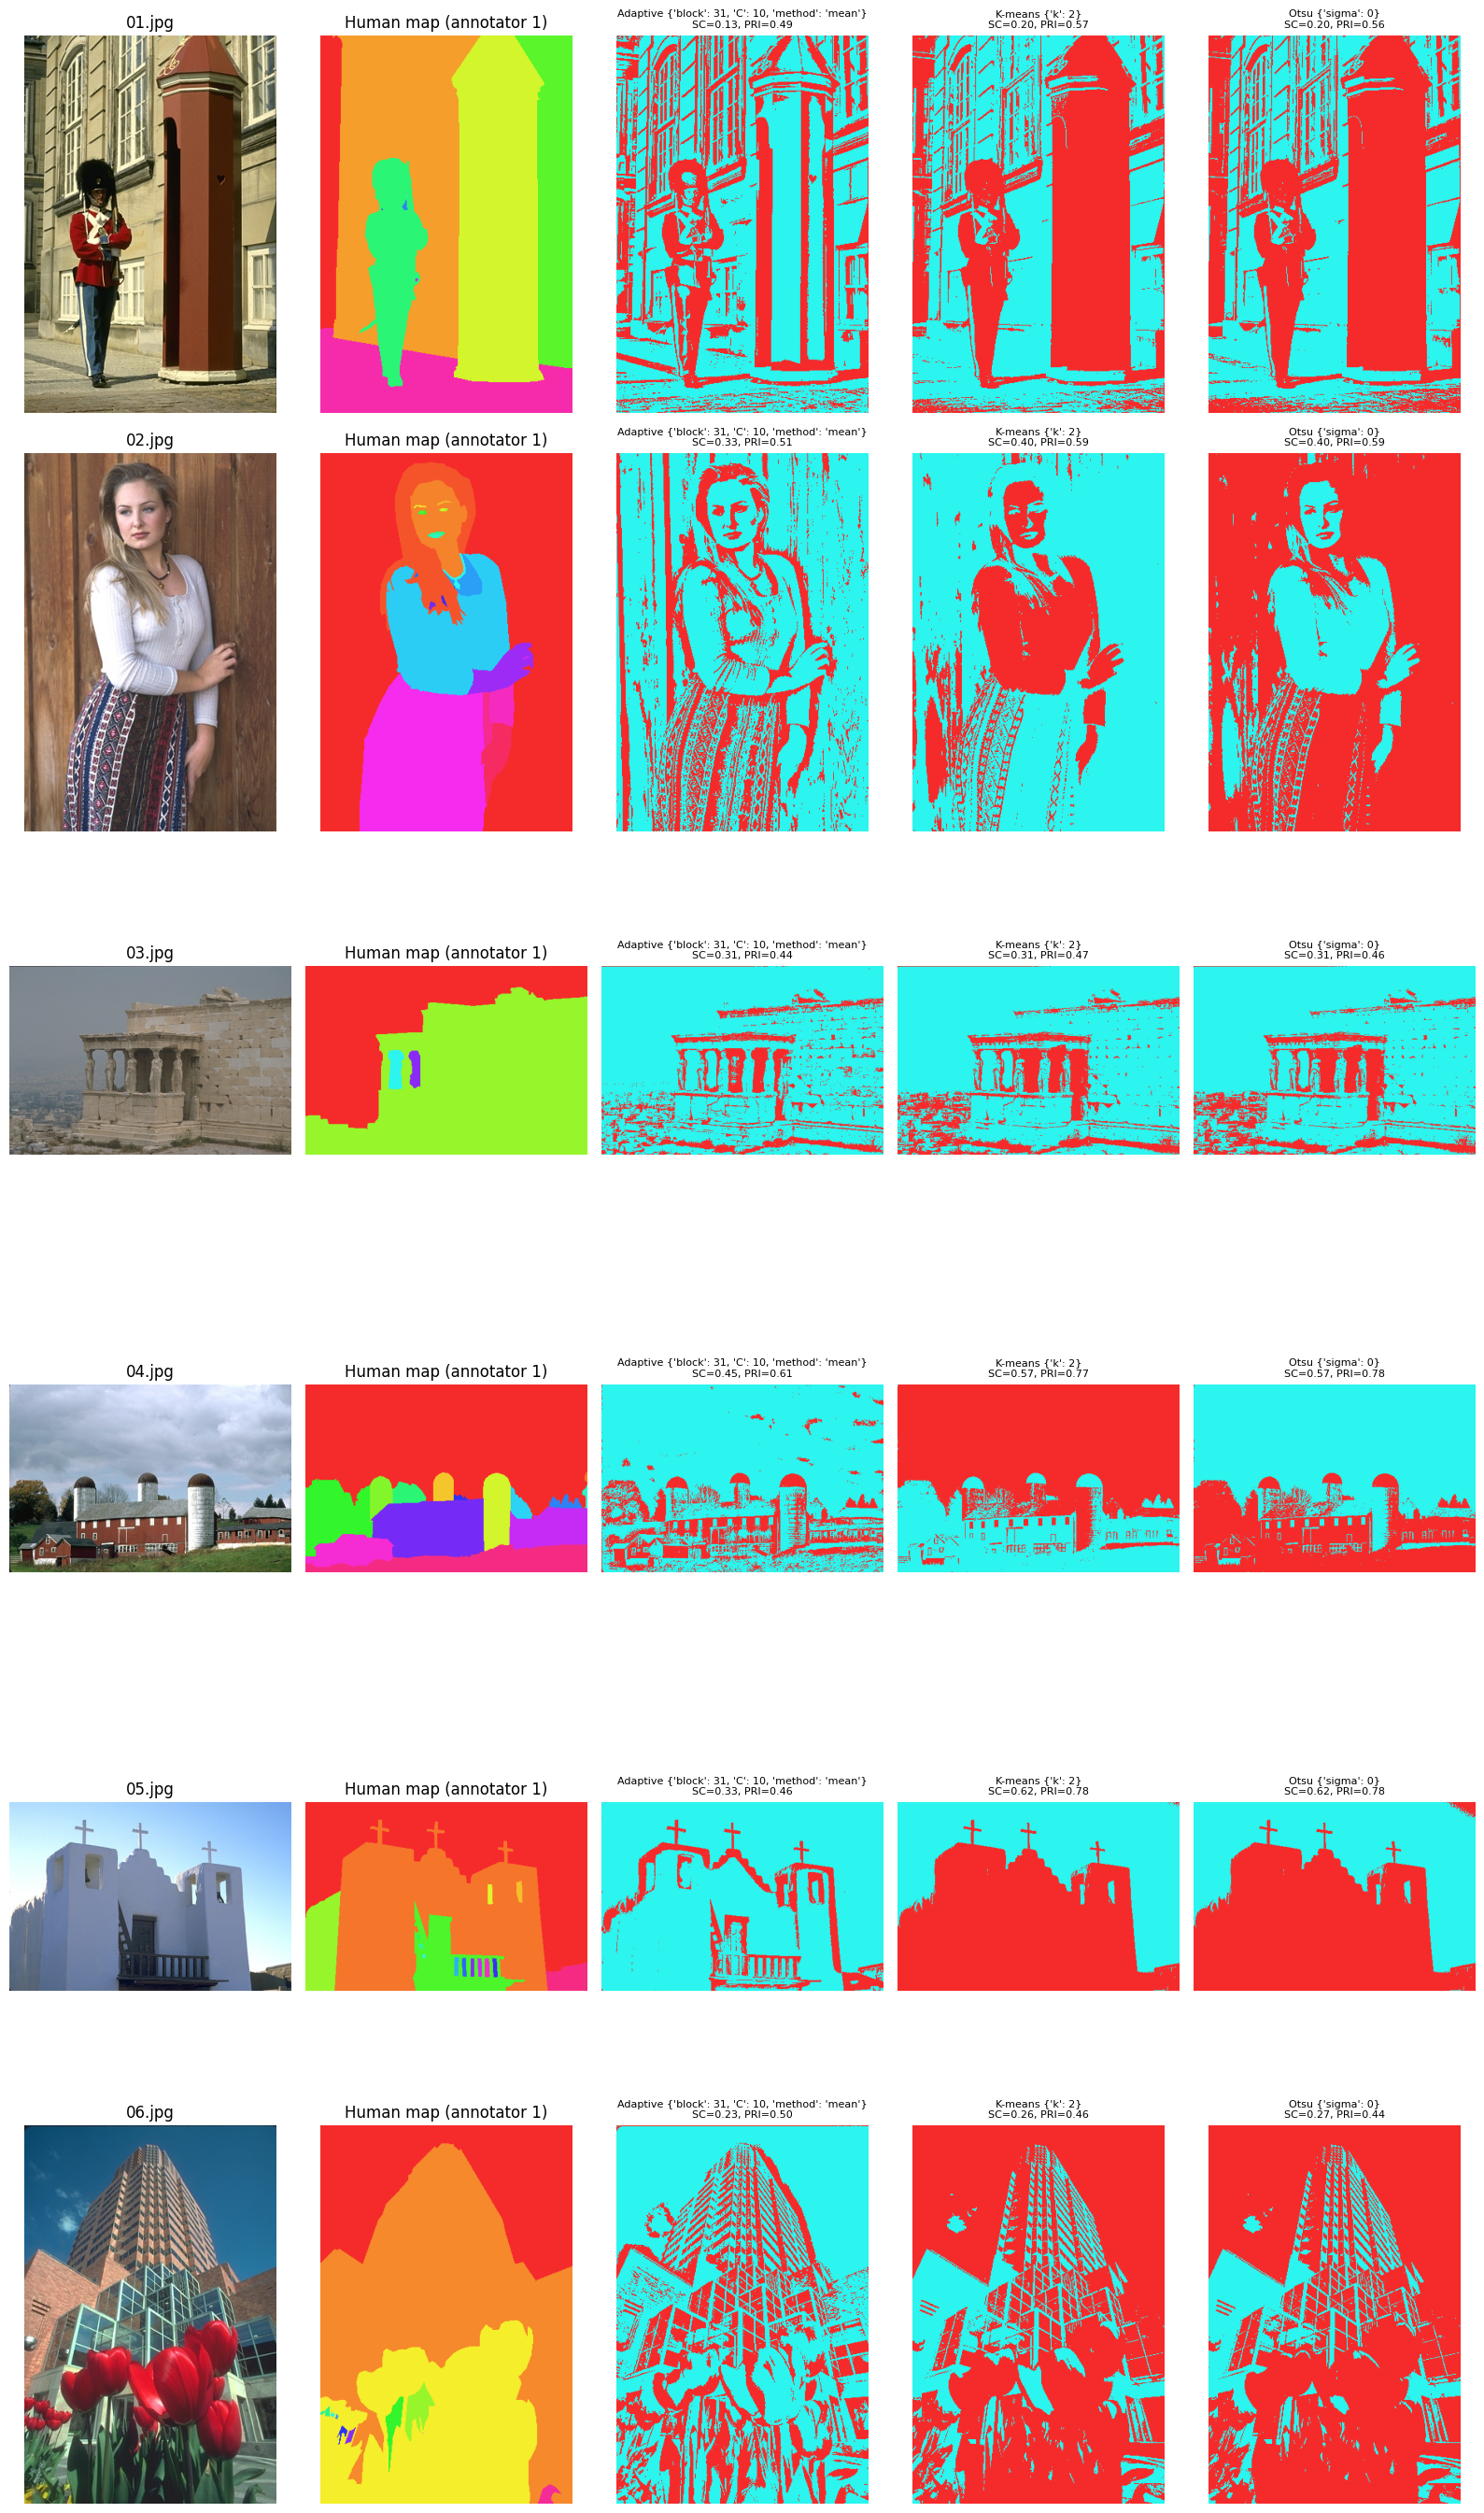

,image,method,SC_annotator_1,SC_annotator_2,SC_annotator_3,SC_annotator_4,SC_annotator_5,PRI_annotator_1,PRI_annotator_2,PRI_annotator_3,PRI_annotator_4,PRI_annotator_5,SC_annotator_6,PRI_annotator_6
0,01,Adaptive,0.213,0.121,0.104,0.077,0.115,0.497,0.485,0.488,0.487,0.484,NaN,NaN
1,01,K-means,0.356,0.213,0.152,0.118,0.186,0.615,0.576,0.551,0.549,0.564,NaN,NaN
2,01,Otsu,0.343,0.203,0.143,0.114,0.173,0.599,0.570,0.543,0.545,0.557,NaN,NaN
3,02,Adaptive,0.372,0.371,0.366,0.374,0.136,0.525,0.524,0.521,0.525,0.443,0.372,0.524
4,02,K-means,0.449,0.449,0.429,0.454,0.137,0.621,0.621,0.618,0.624,0.446,0.452,0.623
5,02,Otsu,0.457,0.456,0.435,0.461,0.139,0.621,0.621,0.619,0.624,0.423,0.460,0.623
6,03,Adaptive,0.441,0.357,0.235,0.260,0.236,0.491,0.449,0.415,0.438,0.425,NaN,NaN
7,03,K-means,0.434,0.363,0.245,0.265,0.251,0.492,0.470,0.447,0.459,0.461,NaN,NaN
8,03,Otsu,0.435,0.365,0.246,0.264,0.251,0.492,0.471,0.446,0.456,0.460,NaN,NaN
9,04,Adaptive,0.434,0.503,0.426,0.493,0.468,0.614,0.614,0.617,0.614,0.615,0.368,0.569


In [13]:
DISPLAY_IDS = list(DATA)
fig, axes = plt.subplots(len(DISPLAY_IDS), 5, figsize=(16, 4.5 * len(DISPLAY_IDS)), squeeze=False)
seg_image_scores = {}
for row_index, image_id in enumerate(DISPLAY_IDS):
    data = DATA[image_id]
    axes[row_index, 0].imshow(data["rgb"]); axes[row_index, 0].set_title(f"{image_id}.jpg")
    axes[row_index, 1].imshow(colorize_labels(data["seg"][0]))
    axes[row_index, 1].set_title("Human map (annotator 1)")
    for column, (_, result) in enumerate(best_seg.iterrows()):
        params = result["_params"]
        labels = SEGMENTERS[result["method"]](data, **params)
        scores = seg_scores(labels, data)
        seg_image_scores[(image_id, result["method"])] = scores
        axes[row_index, column + 2].imshow(colorize_labels(labels))
        axes[row_index, column + 2].set_title(
            f"{result['method']} {params}\nSC={scores['SC']:.2f}, PRI={scores['PRI']:.2f}",
            fontsize=8)
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

# Show per-annotator scores to make reference disagreement visible.
rows = []
for (image_id, method), scores in seg_image_scores.items():
    rows.append({"image":image_id, "method":method,
                 **{f"SC_annotator_{k+1}":round(v,3) for k,v in enumerate(scores["SC_each"])},
                 **{f"PRI_annotator_{k+1}":round(v,3) for k,v in enumerate(scores["PRI_each"])}})
display(pd.DataFrame(rows))


## 3. Summary and analysis

In [14]:
print("=== Edge detection: best per method ===")
display(best_edge)
print("=== Region segmentation: best per method ===")
display(best_seg.drop(columns="_params"))


=== Edge detection: best per method ===


,method,sigma,ksize,ODS,AP,best_threshold
0,Laplacian,1,3,0.674,0.566,0.15
1,LoG,2,13,0.676,0.568,0.15
2,Prewitt,1,3,0.691,0.615,0.22
3,Sobel,1,3,0.690,0.614,0.22


=== Region segmentation: best per method ===


,method,params,SC,PRI
0,Adaptive,"{'block': 31, 'C': 10, 'method': 'mean'}",0.295,0.501
1,K-means,{'k': 2},0.394,0.607
2,Otsu,{'sigma': 0},0.394,0.602


### Analysis notes

Use the tables and figures generated by the current run; do not copy scores from an earlier run.

**Edge detection**
- Compare ODS and AP: ODS is the best F-measure at one shared threshold; AP summarizes performance over thresholds.
- Sobel and Prewitt use first derivatives. Smoothing and larger kernels can reduce texture responses, but may weaken fine boundaries.
- Roberts responds to small intensity changes and is sensitive to noise. Laplacian and LoG use zero crossings; LoG smooths before taking the second derivative.
- A lower threshold generally keeps more weak edges and raises recall, while also adding false edges. A higher threshold removes weak responses but may break faint contours.

**Region segmentation**
- Otsu chooses one global intensity threshold. It may struggle with uneven illumination.
- Adaptive thresholding uses local neighborhoods. Compare window size and `C` to see how local illumination and fragmentation change.
- K-means groups pixels by Lab colour. Changing `K` changes how many colour groups are produced; this method has no explicit object understanding.
- PRI and Segmentation Covering measure different kinds of agreement with human maps. Discuss both and inspect the visual examples.

**Limitations**
Texture, shadows, illumination changes, and disagreement among human annotations can affect all classical methods.